# jPCA explained from scratch — a hands-on companion

This notebook is a slow walk through the method used in notebooks 00–01. No real
data, no statistics — just toy systems small enough to see through completely.
Every idea comes twice: once in text, once as code you can run and poke.
(Best read *before* the other notebooks.)

**The whole method in one sentence:** jPCA fits the simplest possible dynamical
system to the population's trajectory — *dX/dt = M·X* — and then keeps only the
part of M that **rotates**.

1. the state-space picture — what "population state" even means
2. fitting a law of motion to a trajectory (it is just regression)
3. why *skew-symmetric* means *pure rotation*
4. how one fitted matrix becomes "rotation planes" and the famous loop figure
5. what a rotation means biologically: patterns chasing patterns
6. the catch: jPCA always finds rotations — so what counts as evidence?

**Python reading hints for MATLAB eyes** (used throughout):

- `@` is matrix multiply (MATLAB `*`); plain `*` is element-wise (MATLAB `.*`)
- `X.T` is transpose (MATLAB `X.'`); `X[:, :-1]` = all columns except the last
- indexing starts at 0, and ranges exclude the last element (`0:3` ≈ `range(3)`)
- `np.linalg.pinv`, `np.linalg.eig`, `scipy.linalg.expm` = MATLAB `pinv`, `eig`, `expm`

## 1. The state-space picture

Forget individual neurons for a moment. At each instant the whole population is
ONE point:

- the space has one axis per neuron (218 in the real data, 3 in the demo below),
- the coordinates of the point at time t are the firing rates of all neurons at t,
- one trial / condition = one **trajectory** traced by that point as time passes.

Two views of the SAME data below: on the left, three familiar rate-vs-time traces;
on the right, the same three numbers plotted as one dot moving through "neuron
space." jPCA lives entirely in the right-hand view.

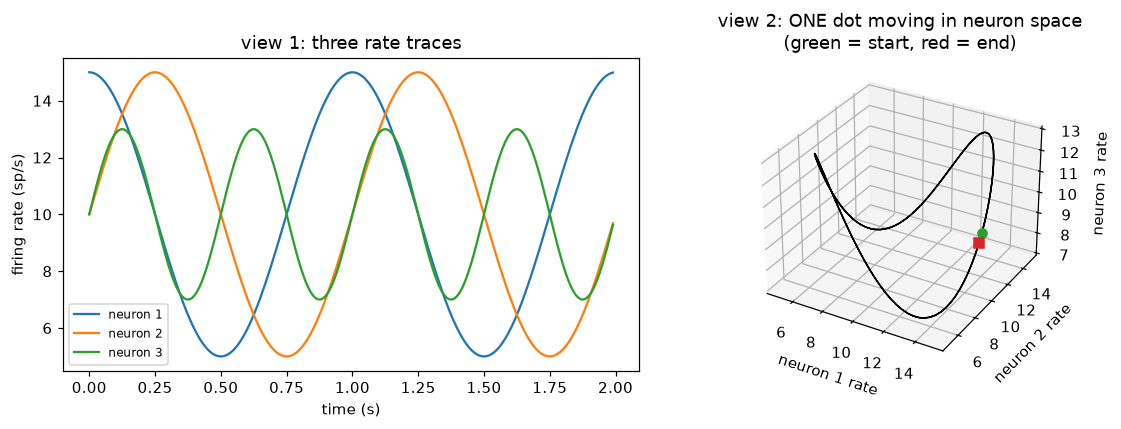

Same data, two views. jPCA asks about the SHAPE of the moving dot's path.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from jpca_core import *
%matplotlib inline
plt.rcParams['figure.dpi'] = 110

# --- One trial, two views ---------------------------------------------------
# A 3-neuron toy population watched for 2 s: three rate traces on the left;
# THE SAME data as one moving dot in "neuron space" on the right.
t = np.arange(0, 2.0, 0.01)            # time axis in seconds, 10 ms steps
r1 = 10 + 5 * np.cos(2 * np.pi * t)    # neuron 1: 1 Hz cosine around 10 sp/s
r2 = 10 + 5 * np.sin(2 * np.pi * t)    # neuron 2: same wave, a quarter-cycle later
r3 = 10 + 3 * np.sin(4 * np.pi * t)    # neuron 3: a faster 2 Hz wiggle

fig = plt.figure(figsize=(11, 4))
ax1 = fig.add_subplot(1, 2, 1)
ax1.plot(t, r1, label='neuron 1')
ax1.plot(t, r2, label='neuron 2')
ax1.plot(t, r3, label='neuron 3')
ax1.set_xlabel('time (s)')
ax1.set_ylabel('firing rate (sp/s)')
ax1.set_title('view 1: three rate traces')
ax1.legend(fontsize=8)

ax2 = fig.add_subplot(1, 2, 2, projection='3d')   # 3-D panel: axes = neuron rates
ax2.plot(r1, r2, r3, color='k', linewidth=1)
ax2.plot(r1[0], r2[0], r3[0], 'o', color='tab:green')    # green dot = start
ax2.plot(r1[-1], r2[-1], r3[-1], 's', color='tab:red')   # red square = end
ax2.set_xlabel('neuron 1 rate')
ax2.set_ylabel('neuron 2 rate')
ax2.set_zlabel('neuron 3 rate')
ax2.set_title('view 2: ONE dot moving in neuron space\n(green = start, red = end)')
fig.tight_layout()
plt.show()
print("Same data, two views. jPCA asks about the SHAPE of the moving dot's path.")

## 2. Fitting a law of motion = regression, nothing more

The simplest possible law of motion for the state X(t):

> **dX/dt = M·X** — "where the state is heading = one fixed matrix × where it is"

We don't know M, but we can estimate it from data. Measure the state in every time
bin (X), and the change between adjacent bins (dX = diff(X)). Then find the M that
makes dX ≈ M·X as closely as possible over all bins. That is an ordinary
least-squares problem; in MATLAB you would write `M = dX / X`.

The demo cooks up a trajectory from a KNOWN matrix, then checks that regression
recovers it. (In the real pipeline this fit happens after PCA, in a 6-D latent
space, with all conditions stacked end to end — same idea, more columns.)

In [2]:
# --- Cook up a trajectory from a KNOWN matrix, then recover M by regression ---
from scipy.linalg import expm          # matrix exponential -- same as MATLAB's expm

dt = 0.01                              # time step (s)
t = np.arange(0, 2.0, dt)
omega = 2 * np.pi * 1.0                # 1 Hz, in radians per second
M_true = np.array([[0.0, -omega],
                   [omega,  0.0]])     # the hidden law of motion (a pure rotator, section 3)

# Generate the trajectory: x(t+dt) = expm(M*dt) @ x(t), starting from (1, 0).
step = expm(M_true * dt)               # expm is the exact update rule for x' = Mx
X = np.zeros((2, len(t)))
X[:, 0] = [1.0, 0.0]
for k in range(len(t) - 1):
    X[:, k + 1] = step @ X[:, k]

# Now forget M_true and estimate it from the trajectory alone:
# dX/dt approx M X   ->   M = (dX/dt) pinv(X)     [MATLAB: M = (dX/dt) / X]
X0 = X[:, :-1]                         # state in every bin except the last
dX = np.diff(X, axis=1)                # change per bin, like MATLAB diff(X, 1, 2)
M_hat = (dX / dt) @ np.linalg.pinv(X0) # least-squares fit of the law of motion
print('the hidden matrix M was:')
print(np.round(M_true, 3))
print('recovered from the trajectory alone:')
print(np.round(M_hat, 3))
print('largest error: %.4f' % np.max(np.abs(M_hat - M_true)))
print('-> fitting a linear dynamical system is just regression (least squares).')

the hidden matrix M was:
[[ 0.    -6.283]
 [ 6.283  0.   ]]
recovered from the trajectory alone:
[[-0.197 -6.279]
 [ 6.279 -0.197]]
largest error: 0.1973
-> fitting a linear dynamical system is just regression (least squares).


You may notice the recovered matrix is not *perfect*: the diagonal came out
−0.197 instead of 0. That is not a bug — it is the finite-difference
approximation. `diff(X)` measures the *chord* between adjacent bins, and for
circular motion the chord points slightly *inward* from the true tangent — so the
fit sees a tiny fake decay (of size ≈ ω²·dt/2) on top of the rotation. Smaller
time bins shrink it. The same subtlety is why the real pipeline keeps the bins
small, and why notebook 01 warns that derivative-based fits get fragile when the
per-bin change is tiny.

## 3. Why "skew-symmetric" is exactly "pure rotation"

Any square matrix splits into two pieces by plain algebra:

> M = (M + Mᵀ)/2  +  (M − Mᵀ)/2  =  symmetric part  +  skew-symmetric part

The two pieces do geometrically different jobs:

- the **symmetric part** stretches or shrinks the state along fixed axes —
  growth, decay, convergence onto attractors;
- the **skew-symmetric part** (defined by M = −Mᵀ) **rotates** the state, and
  does nothing else.

Why is skew the same as rotation? Circular motion at frequency ω is
x(t) = r·cos(ωt), y(t) = r·sin(ωt). Differentiate:

> dx/dt = −ω·y,   dy/dt = ω·x   →   dX/dt = [[0, −ω], [ω, 0]]·X

and that matrix is exactly skew-symmetric. The converse also holds: **every**
skew-symmetric matrix, in any dimension, generates pure rotation — its eigenvalues
are purely imaginary (±iω), and expm(M) is a rotation matrix: it turns vectors
without changing their length.

jPCA's move: fit M to data, keep only its skew-symmetric part, and ask how much of
the motion that part alone explains (that fraction is the R² printed in notebooks
00–01). Below: rotation only, decay only, and both together (a spiral) — so you
can see what "keeping only the rotation" throws away.

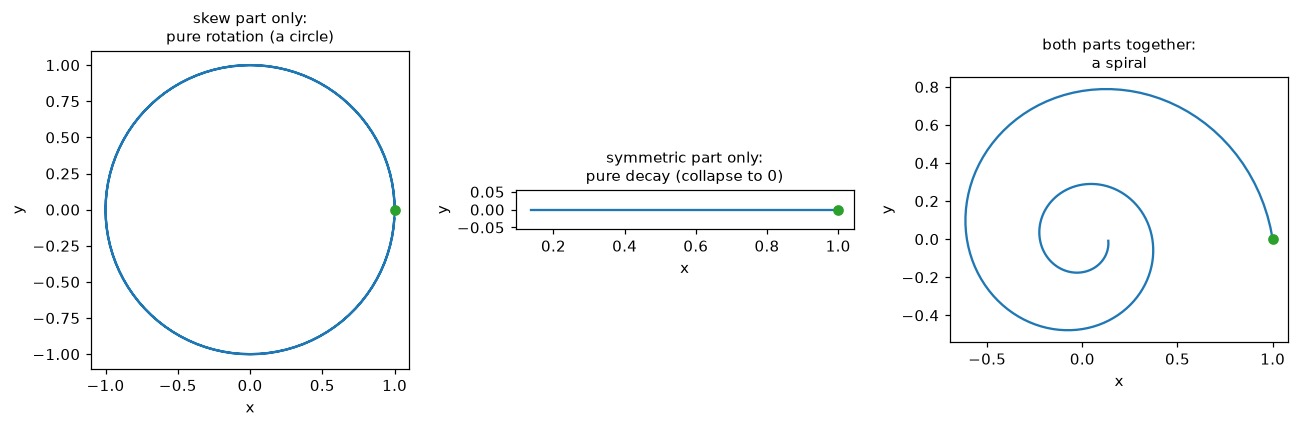

rotator applied over one full period (should be ~ the identity matrix):
[[ 1.  0.]
 [-0.  1.]]
-> a skew matrix turns vectors WITHOUT changing their length. That is all it does.


In [3]:
# --- Same machinery, three trajectories: rotation only, decay only, both ------
M_rot   = np.array([[0.0, -omega],
                    [omega,  0.0]])    # skew-symmetric: M == -M.T (flip + negate)
M_decay = np.array([[-1.0, 0.0],
                    [0.0, -1.0]])      # symmetric: shrinks x and y equally
M_both  = M_decay + M_rot              # any M = symmetric part + skew part

mats  = [M_rot, M_decay, M_both]
names = ['skew part only:\npure rotation (a circle)',
         'symmetric part only:\npure decay (collapse to 0)',
         'both parts together:\na spiral']
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for i in range(3):
    step = expm(mats[i] * dt)
    X = np.zeros((2, len(t)))
    X[:, 0] = [1.0, 0.0]
    for k in range(len(t) - 1):
        X[:, k + 1] = step @ X[:, k]
    axes[i].plot(X[0, :], X[1, :])
    axes[i].plot(X[0, 0], X[1, 0], 'o', color='tab:green')
    axes[i].set_title(names[i], fontsize=10)
    axes[i].set_xlabel('x')
    axes[i].set_ylabel('y')
    axes[i].set_aspect('equal')
fig.tight_layout()
plt.show()

one_turn = expm(M_rot * 1.0)           # advance the rotator by exactly one period
print('rotator applied over one full period (should be ~ the identity matrix):')
print(np.round(one_turn, 6))
print('-> a skew matrix turns vectors WITHOUT changing their length. That is all it does.')

## 4. How ONE matrix becomes "rotation planes" and the loop figure

This is the step everyone gets stuck on. Take it in two sizes.

**In 3D, where you can see it.** In 3D a skew-symmetric matrix is an old friend:
[[0, −c, b], [c, 0, −a], [−b, a, 0]] times a vector is exactly the cross product
(a, b, c) × v. So 3-D skew dynamics = rotation **about an axis**, and the motion
happens **in the plane perpendicular to that axis**. Its eigenvalues are
{0, +iω, −iω}: the 0 belongs to the axis (points on it don't move); the ±iω pair
describes the circling in the plane. The eigenvector of +iω is *complex*,
v = a + ib — and its real part a and imaginary part b are two ordinary real
vectors that span exactly the rotation plane.

**In 6D there is no single axis — instead, up to three independent planes.** A 6×6
skew matrix can rotate in three 2-D planes *at once*, each at its own frequency,
like three gears inside one machine. `eig(M_skew)` hands you all three: the
eigenvalues come in pure-imaginary pairs ±iω₁, ±iω₂, ±iω₃, and each pair's
eigenvector v = a + ib supplies that plane's two spanning directions. The
frequency you read off, ω/2π, is the number printed as "Hz" in notebooks 00–01.

**The loop figure is then just a change of coordinates.** For each time point,
project the state onto the plane's two directions: coordinate 1 = a·Z(t),
coordinate 2 = b·Z(t) — two dot products per time point. Plot coordinate 2 against
coordinate 1 as time runs. If the dynamics in that plane really is a rotation, the
plot traces a loop. That plot *is* the famous jPCA figure.

Below: first the 3-D case, then a 6-D system built BY HAND with two rotation
planes, so we can watch `eig()` recover them and draw the loop figure ourselves.

In [4]:
# --- 3D: a skew matrix = rotation about an axis -------------------------------
# Rotation about the z-axis at 1 Hz: x and y chase each other, z does nothing.
M3 = np.array([[0.0, -omega, 0.0],
               [omega,  0.0, 0.0],
               [0.0,   0.0,  0.0]])
eigvals3, eigvecs3 = np.linalg.eig(M3)   # like MATLAB [V, D] = eig(M)
print('eigenvalues of the 3-D skew matrix:', np.round(eigvals3, 3))
print('one is zero         -> the rotation AXIS (points on it do not move)')
print('two are +/- i*omega -> the rotation PLANE and its speed')

i = np.argmax(eigvals3.imag)             # position of the +i*omega eigenvalue
v = eigvecs3[:, i]                       # its (complex) eigenvector
a3 = v.real / np.linalg.norm(v.real)     # real part      -> one unit vector
b3 = v.imag / np.linalg.norm(v.imag)     # imaginary part -> a second unit vector
print()
print('eigenvector v =', np.round(v, 3))
print('real part a =', np.round(a3, 3))
print('imag part b =', np.round(b3, 3))
print('a . b = %.3f -> perpendicular' % (a3 @ b3))
print('both have zero z-component: the plane they span is the xy-plane,')
print('the plane perpendicular to the rotation axis (z).')

eigenvalues of the 3-D skew matrix: [0.+6.283j 0.-6.283j 0.+0.j   ]
one is zero         -> the rotation AXIS (points on it do not move)
two are +/- i*omega -> the rotation PLANE and its speed

eigenvector v = [0.707+0.j    0.   -0.707j 0.   +0.j   ]
real part a = [1. 0. 0.]
imag part b = [ 0. -1.  0.]
a . b = 0.000 -> perpendicular
both have zero z-component: the plane they span is the xy-plane,
the plane perpendicular to the rotation axis (z).


eigenvalues of M6: [0.+6.28j 0.-6.28j 0.+2.51j 0.-2.51j 0.+0.j   0.+0.j  ]
two pure-imaginary pairs (the two rotation planes) + two zeros (dead directions)


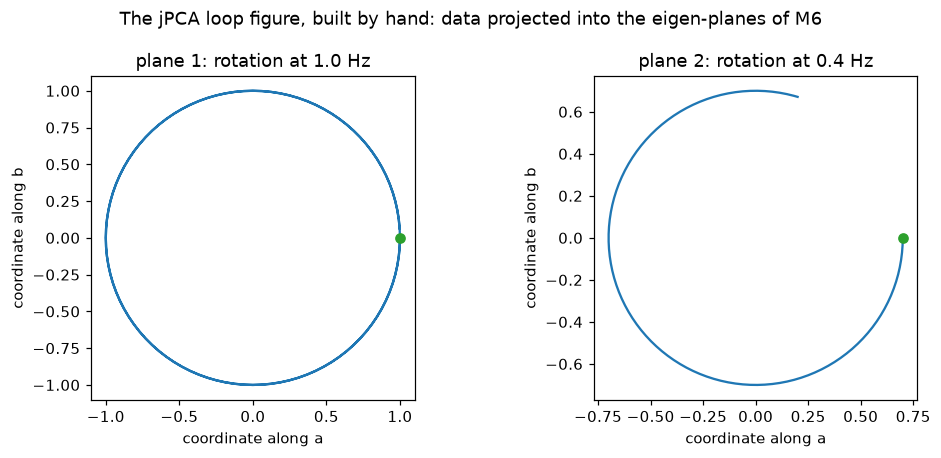

Every loop figure in notebooks 00-01 is made exactly this way.


In [5]:
# --- 6D: eig() finds the planes automatically -- the loop figure, by hand -----
# Build a 6x6 skew matrix containing TWO independent rotation blocks:
omega1 = 2 * np.pi * 1.0               # plane A (coordinates 1-2): 1.0 Hz
omega2 = 2 * np.pi * 0.4               # plane B (coordinates 3-4): 0.4 Hz
M6 = np.zeros((6, 6))                  # coordinates 5-6: no dynamics at all
M6[0, 1] = -omega1
M6[1, 0] = omega1
M6[2, 3] = -omega2
M6[3, 2] = omega2

# Simulate a 6-D trajectory starting from a point inside both planes
X6 = np.zeros((6, len(t)))
X6[:, 0] = [1.0, 0.0, 0.7, 0.0, 0.0, 0.0]
step6 = expm(M6 * dt)
for k in range(len(t) - 1):
    X6[:, k + 1] = step6 @ X6[:, k]

# This is exactly what jpca() does at jpca_core.py:97 -- eigendecompose M_skew.
eigvals6, eigvecs6 = np.linalg.eig(M6)
print('eigenvalues of M6:', np.round(eigvals6, 2))
print('two pure-imaginary pairs (the two rotation planes) + two zeros (dead directions)')

fastest_first = np.argsort(-eigvals6.imag)   # sort by rotation speed, fastest first
fig, axes = plt.subplots(1, 2, figsize=(9.5, 4.2))
for i in range(2):
    v = eigvecs6[:, fastest_first[i]]        # eigenvector of one +/-i*omega pair
    a = v.real / np.linalg.norm(v.real)      # plane direction 1
    b = v.imag / np.linalg.norm(v.imag)      # plane direction 2
    coord1 = a @ X6                          # project the trajectory into the plane:
    coord2 = b @ X6                          # one dot product per direction per time point
    freq_hz = eigvals6.imag[fastest_first[i]] / (2 * np.pi)
    axes[i].plot(coord1, coord2)
    axes[i].plot(coord1[0], coord2[0], 'o', color='tab:green')
    axes[i].set_title('plane %d: rotation at %.1f Hz' % (i + 1, freq_hz))
    axes[i].set_xlabel('coordinate along a')
    axes[i].set_ylabel('coordinate along b')
    axes[i].set_aspect('equal')
fig.suptitle('The jPCA loop figure, built by hand: data projected into the eigen-planes of M6')
fig.tight_layout()
plt.show()
print('Every loop figure in notebooks 00-01 is made exactly this way.')

## 5. What a rotation means biologically: patterns chasing patterns

A "pattern" is one number per neuron — a population-wide shape of activity
("neurons 4–8 loud, the rest quiet" is a pattern). Suppose the state rotates in
the plane spanned by two patterns a and b:

> X(t) = a·cos(ωt) + b·sin(ωt)

Read that aloud: at phase 0 the population activity IS pattern a. A quarter-cycle
later cos has faded and sin has grown, so the population IS pattern b. Then −a
(the same shape, sign-flipped), then −b, then back to a. **A rotation in state
space = the population endlessly morphing through a → b → −a → −b.** The first
figure below freezes one cycle at 8 moments so you can watch the morphing.

Now the single-neuron view. Neuron i's rate is

> rate_i(t) = a_i·cos(ωt) + b_i·sin(ωt) = R_i·cos(ωt − φ_i)

(any mixture A·cos + B·sin is a single cosine with some amplitude R and phase φ).
So **every neuron oscillates at the same frequency, but each at its own phase** —
each neuron peaks at its own time. That is the second figure, left panel.

And now the punchline. Neurons peaking one after another *is what a sequence is*.
Sort the neurons by their phase (= peak time) and stack their rates as an image:
a traveling wave appears (middle panel). The same data in state space is a loop
(right panel). **"The population state rotates" and "the neurons fire in a
phase-shifted sequence" are two descriptions of ONE object.**

That is why jPCA reports rotations for pure feedforward sequences (notebook 01),
and why the loop figure alone cannot tell you whether any dynamical machinery
produced them. It is a display format for phase-ordered structure — not a
detector of an engine.

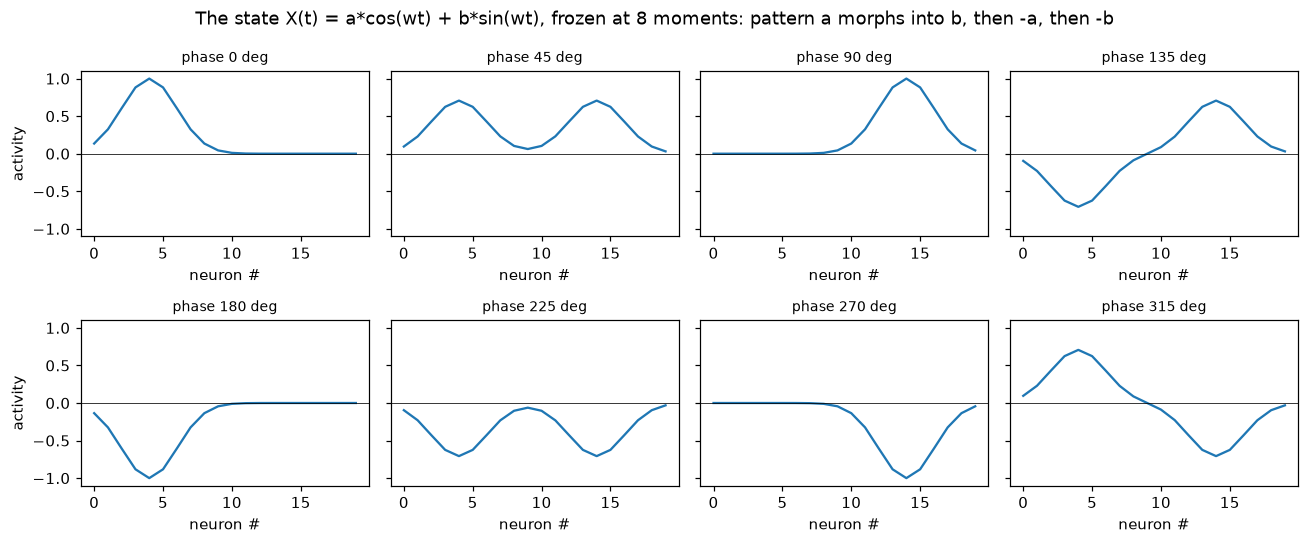

In [6]:
# --- One rotation cycle = the population morphing a -> b -> -a -> -b -> a -----
n_neurons = 20
neuron_axis = np.arange(n_neurons)
pattern_a = np.exp(-(neuron_axis - 4) ** 2 / (2 * 2.0 ** 2))    # bump around neuron 4
pattern_b = np.exp(-(neuron_axis - 14) ** 2 / (2 * 2.0 ** 2))   # bump around neuron 14

phases_deg = [0, 45, 90, 135, 180, 225, 270, 315]   # 8 snapshots around one cycle
fig, axes = plt.subplots(2, 4, figsize=(12, 5), sharey=True)
for i in range(8):
    phase = np.radians(phases_deg[i])               # degrees -> radians
    state = pattern_a * np.cos(phase) + pattern_b * np.sin(phase)  # X(t) at this moment
    ax = axes[i // 4, i % 4]                        # panel i -> its (row, column)
    ax.plot(neuron_axis, state)
    ax.axhline(0, color='k', linewidth=0.5)
    ax.set_ylim(-1.1, 1.1)
    ax.set_title('phase %d deg' % phases_deg[i], fontsize=9)
    ax.set_xlabel('neuron #')
axes[0, 0].set_ylabel('activity')
axes[1, 0].set_ylabel('activity')
fig.suptitle('The state X(t) = a*cos(wt) + b*sin(wt), frozen at 8 moments: '
             'pattern a morphs into b, then -a, then -b')
fig.tight_layout()
plt.show()

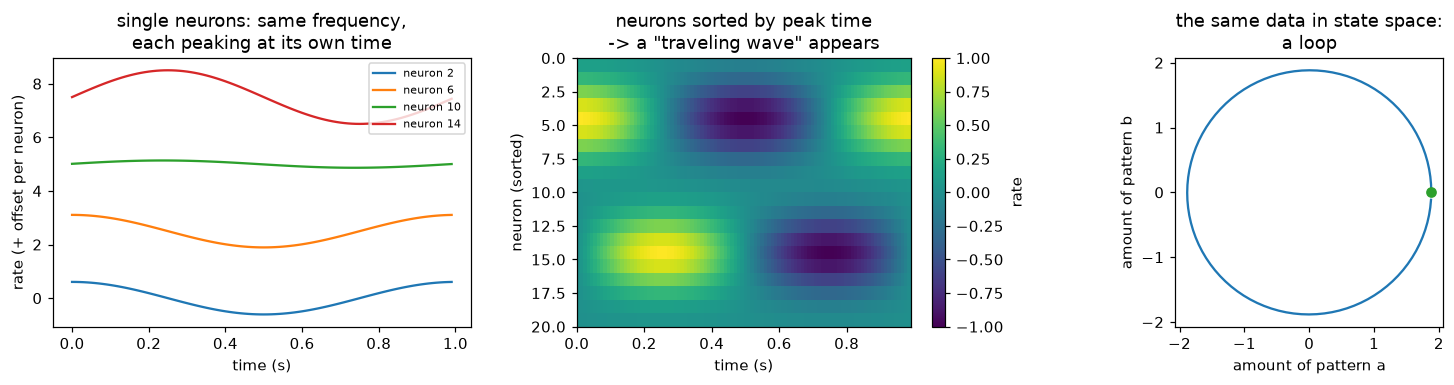

Sequence (panel 2) and rotation (panel 3) are two views of ONE dataset.


In [7]:
# --- Same rotation, seen by single neurons: one wave, many phases -------------
t1 = np.arange(0, 1.0, dt)                # one full 1 Hz cycle
rates = np.zeros((n_neurons, len(t1)))
for i in range(n_neurons):                # neuron i = its own mixture of a and b
    rates[i, :] = pattern_a[i] * np.cos(2 * np.pi * t1) + pattern_b[i] * np.sin(2 * np.pi * t1)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))

# panel 1: a few single-neuron time courses (stacked vertically for visibility)
example_neurons = [2, 6, 10, 14]
for k in range(len(example_neurons)):
    neuron = example_neurons[k]
    axes[0].plot(t1, rates[neuron, :] + 2.5 * k, label='neuron %d' % neuron)
axes[0].set_title('single neurons: same frequency,\neach peaking at its own time')
axes[0].set_xlabel('time (s)')
axes[0].set_ylabel('rate (+ offset per neuron)')
axes[0].legend(fontsize=7)

# panel 2: all neurons, sorted by peak time -> the "traveling wave"
peak_bin = np.argmax(rates, axis=1)       # bin where each neuron peaks
order = np.argsort(peak_bin)              # neuron order sorted by peak time
im = axes[1].imshow(rates[order, :], aspect='auto', cmap='viridis',
                    extent=[t1[0], t1[-1], n_neurons, 0])
axes[1].set_title('neurons sorted by peak time\n-> a "traveling wave" appears')
axes[1].set_xlabel('time (s)')
axes[1].set_ylabel('neuron (sorted)')
fig.colorbar(im, ax=axes[1], label='rate')

# panel 3: the SAME data in state space -> the loop
a_hat = pattern_a / np.linalg.norm(pattern_a)
b_hat = pattern_b / np.linalg.norm(pattern_b)
coord1 = a_hat @ rates                    # how much of pattern a is present, over time
coord2 = b_hat @ rates                    # how much of pattern b
axes[2].plot(coord1, coord2)
axes[2].plot(coord1[0], coord2[0], 'o', color='tab:green')
axes[2].set_title('the same data in state space:\na loop')
axes[2].set_xlabel('amount of pattern a')
axes[2].set_ylabel('amount of pattern b')
axes[2].set_aspect('equal')
fig.tight_layout()
plt.show()
print('Sequence (panel 2) and rotation (panel 3) are two views of ONE dataset.')

## 6. The catch: jPCA *always* finds rotations

Notice what the procedure does: it fits the best linear flow, keeps only the
rotational part, and then finds the planes where that rotation looks strongest.
jPCA does not test "is this data rotational?" — it **searches for the most
rotational description** of the data. It will always return planes, frequencies,
and loops.

So the loops' existence is never the evidence. The evidence is:

- **R²** — how much of the observed motion the rotation actually explains
  (notebooks 00–01 print this; on the real maze data it is 0.146 in the full
  window),
- **surrogates** — does shuffled / phase-scrambled data rotate just as much?
- **meaning** — do the planes and frequencies correspond to anything physical?

**Recap of the whole method, in five lines:**

1. stack all conditions' trajectories into one cloud of states,
2. PCA down to a few latent dimensions,
3. regress dX/dt = M·X — ordinary least squares,
4. keep only the skew-symmetric part of M — the pure rotation,
5. read planes and frequencies off its imaginary eigenvalue pairs, and project
   the data into the planes → the loop figure.

**Where next:** notebook 00 runs this pipeline on the real Churchland 2012 data,
and notebook 01 shows why pure sequences pass the same test — the Lebedev/Kuzmina
challenge.